# Задание 11. Модель обнаружения опасных ссылок

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

Код — `ml/train_url.py` (без ноутбука: `python -m ml.train_url`). Данные — задание 10: 100 000 URL PhiUSIIL,
каноническая форма `http://домен`, разбиение по регистрируемому домену.

**Признаки.** Первая версия модели использовала только 17 числовых признаков домена (задание 10). На validation она дала
ROC-AUC 0,81 при любом алгоритме. После удаления артефакта разметки модель видит только сам домен, а числовых признаков
для него мало. Поэтому к ним добавлены **символьные 2–5-граммы домена (TF-IDF)** — они вычисляются из той же строки URL,
без обращения к сети. Выбор сделан по validation; первая версия один раз оценивалась на test (ROC-AUC 0,858) — это указано
в отчёте.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, auc, precision_recall_curve, roc_curve

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)

from ml import train_url as tu  # noqa: E402
from ml.url_features import explain_url, extract_url_features  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
data = tu.load_data()
pd.DataFrame({k: {"URL": len(v), "фишинг": int(v["label"].sum()), "доля фишинга, %": round(v["label"].mean() * 100, 2)}
              for k, v in data.items()}).T

,URL,фишинг,"доля фишинга, %"
train,70098.0,27121.0,38.69
val,14052.0,4831.0,34.38
test,15850.0,6510.0,41.07


## 1. Сравнение алгоритмов

| Алгоритм | Признаки | Сетка (GridSearchCV, 3 фолда StratifiedGroupKFold по домену, F2) |
| :--- | :--- | :--- |
| Logistic Regression | 17 числовых (StandardScaler) + n-граммы домена (TF-IDF) | `C` ∈ {0,3; 1; 3; 10} |
| Random Forest (200 деревьев) | 17 числовых + 3000 самых частых n-грамм | `min_samples_leaf` ∈ {2; 5} |

Пороги на validation:
* **t1** (SAFE / SUSPICIOUS) — максимальный порог, при котором Recall ≥ 0,85 (минимальное требование раздела 3.4):
  не более 15% фишинга попадает в SAFE;
* **t2** (SUSPICIOUS / DANGEROUS) — минимальный порог, при котором Precision ≥ 0,90: категория DANGEROUS верна
  не менее чем в 90% случаев.

Первая версия порогов (t1 по Recall ≥ 0,95, t2 по Precision ≥ 0,95) дала t1 = 0,068 и относила к SUSPICIOUS 60%
безопасных доменов validation (5518 из 9221), в том числе google.com. Пороги пересмотрены по validation; первая
версия один раз оценивалась на test — её результаты приведены в отчёте.

In [2]:
start = time.perf_counter()
results, models = tu.run_comparison(data, verbose=False)
print(f"Сравнение заняло {time.perf_counter() - start:.0f} с")


def summary(r, key):
    m = r[key]
    return {"Алгоритм": r["title"], "Параметры": r["best_params"], "CV F2": r["cv_f2"], "Порог": m["threshold"],
            "Accuracy": m["accuracy"], "Precision": m["precision"], "Recall": m["recall"], "F1": m["f1"],
            "F2": m["f2"], "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"],
            "Обучение, с": r["fit_seconds"], "Предсказание, мс": r["predict_ms"]}


print("Validation, порог t1 (Recall ≥ 0,85):")
pd.DataFrame([summary(r, "val_at_t1") for r in results]).set_index("Алгоритм")

Сравнение заняло 463 с
Validation, порог t1 (Recall ≥ 0,85):


,Параметры,CV F2,Порог,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,"Обучение, с","Предсказание, мс"
Алгоритм,,,,,,,,,,,,
Logistic Regression,{'C': 10},0.7799,0.2003,0.7495,0.5950,0.8499,0.7000,0.7828,0.8914,0.8718,90.6,3.14
Random Forest,{'min_samples_leaf': 5},0.7382,0.2764,0.7388,0.5823,0.8501,0.6912,0.7785,0.8862,0.8673,362.0,44.09


In [3]:
print("Validation при пороге 0,5 и при t2:")
pd.DataFrame([{**{f"{k} @0,5": r["val_at_0_5"][k] for k in ("precision", "recall", "f1")},
               **{f"{k} @t2": r["val_at_t2"][k] for k in ("precision", "recall", "f1")}, "t1": r["t1"], "t2": r["t2"]}
              for r in results], index=[r["title"] for r in results])

Validation при пороге 0,5 и при t2:


,"precision @0,5","recall @0,5","f1 @0,5",precision @t2,recall @t2,f1 @t2,t1,t2
Logistic Regression,0.8176,0.7239,0.7679,0.9001,0.6661,0.7656,0.2003,0.6638
Random Forest,0.8948,0.6638,0.7622,0.9001,0.6582,0.7604,0.2764,0.5082


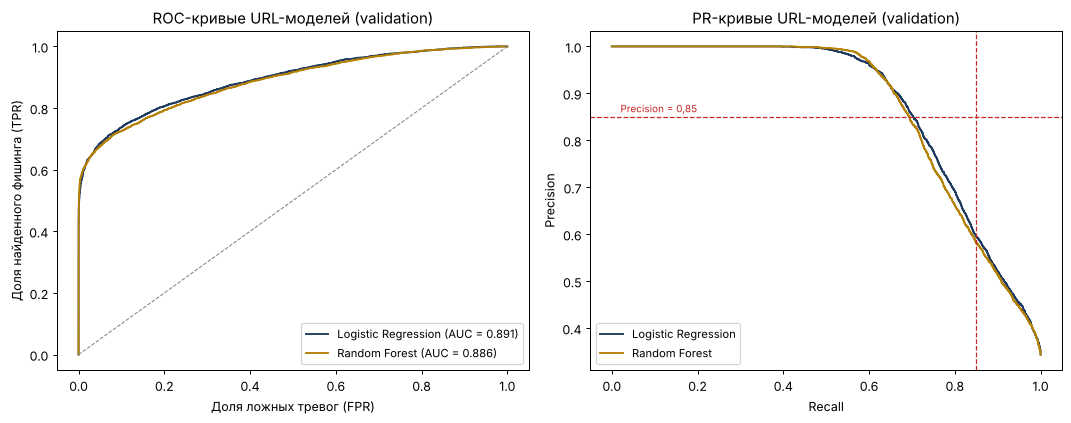

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
y_val = data["val"]["label"].to_numpy()
colors = {"logreg": "#1f3a5f", "random_forest": "#b58105"}
probas = {name: m.predict_proba(data["val"][tu.X_COLS])[:, 1] for name, m in models.items()}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{tu.TITLES[name]} (AUC = {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, color=colors[name], label=tu.TITLES[name])
axes[0].plot([0, 1], [0, 1], "--", color="grey", linewidth=0.8)
axes[0].set_xlabel("Доля ложных тревог (FPR)")
axes[0].set_ylabel("Доля найденного фишинга (TPR)")
axes[0].set_title("ROC-кривые URL-моделей (validation)")
axes[1].axhline(0.85, color="#c62828", linestyle="--", linewidth=1)
axes[1].axvline(0.85, color="#c62828", linestyle="--", linewidth=1)
axes[1].text(0.02, 0.86, "Precision = 0,85", color="#c62828", fontsize=8)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("PR-кривые URL-моделей (validation)")
for ax in axes:
    ax.legend(fontsize=9, loc="lower right" if ax is axes[0] else "lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_roc_pr_url.png", dpi=150)

## 2. Важность признаков

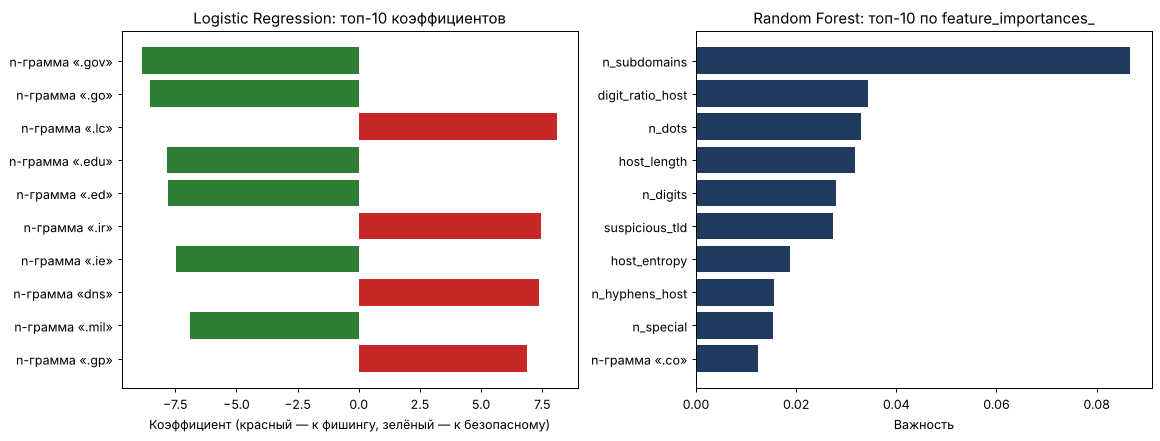

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ("logreg", "random_forest")):
    imp = tu.feature_importance(models[name])
    top = imp.reindex(imp.abs().sort_values(ascending=False).index).head(10)[::-1]
    colors_bar = ["#c62828" if v > 0 else "#2e7d32" for v in top] if name == "logreg" else "#1f3a5f"
    ax.barh(top.index, top.values, color=colors_bar)
    ax.set_title(f"{tu.TITLES[name]}: топ-10 " + ("коэффициентов" if name == "logreg" else "по feature_importances_"))
    ax.set_xlabel("Коэффициент (красный — к фишингу, зелёный — к безопасному)" if name == "logreg" else "Важность")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_url_feature_importance.png", dpi=150)

In [6]:
imp_lr = tu.feature_importance(models["logreg"])
print("Logistic Regression — коэффициенты 17 числовых признаков (после стандартизации):")
imp_lr[[i for i in imp_lr.index if not i.startswith("n-грамма")]].sort_values(ascending=False).round(3)

Logistic Regression — коэффициенты 17 числовых признаков (после стандартизации):


has_ip                2.578
n_subdomains          2.248
has_punycode          1.739
is_shortener          1.288
suspicious_tld        1.031
n_digits              0.831
host_length           0.549
digit_ratio_host      0.498
nonstandard_port      0.326
n_suspicious_words    0.161
n_hyphens_host        0.151
n_special             0.151
brand_in_url          0.132
host_entropy          0.065
brand_similarity      0.003
mixed_scripts         0.000
n_dots               -0.658
dtype: float64

## 3. Выбор модели и пороги

In [7]:
best = tu.choose_best(results)
model = models[best["name"]]
print(f"Выбрана: {best['title']} {best['best_params']}; t1 = {best['t1']}, t2 = {best['t2']}")
p_best = probas[best["name"]]
cats = pd.Series([tu.category(p, best["t1"], best["t2"]) for p in p_best])
pd.crosstab(cats, pd.Series(y_val).map({0: "безопасный", 1: "фишинг"}), margins=True,
            margins_name="всего").reindex(["SAFE", "SUSPICIOUS", "DANGEROUS", "всего"])

Выбрана: Logistic Regression {'C': 10}; t1 = 0.2003, t2 = 0.6638


col_0,безопасный,фишинг,всего
row_0,,,
SAFE,6426,725,7151
SUSPICIOUS,2438,888,3326
DANGEROUS,357,3218,3575
всего,9221,4831,14052


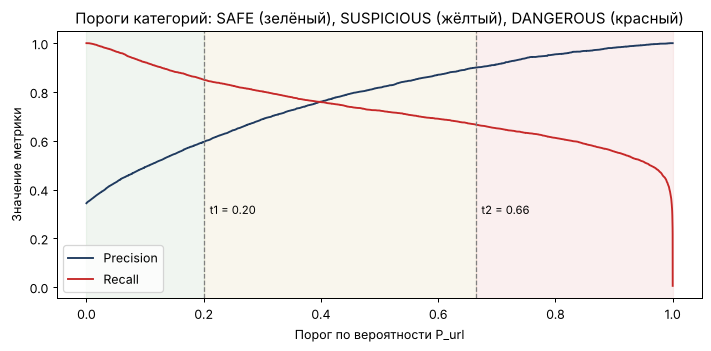

In [8]:
prec, rec, thr = precision_recall_curve(y_val, p_best)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec[:-1], label="Precision", color="#1f3a5f")
ax.plot(thr, rec[:-1], label="Recall", color="#c62828")
for t, name in ((best["t1"], "t1"), (best["t2"], "t2")):
    ax.axvline(t, color="grey", linestyle="--", linewidth=1)
    ax.text(t + 0.01, 0.3, f"{name} = {t:.2f}", fontsize=9)
ax.axvspan(0, best["t1"], color="#2e7d32", alpha=0.07)
ax.axvspan(best["t1"], best["t2"], color="#b58105", alpha=0.07)
ax.axvspan(best["t2"], 1, color="#c62828", alpha=0.07)
ax.set_xlabel("Порог по вероятности P_url")
ax.set_ylabel("Значение метрики")
ax.set_title("Пороги категорий: SAFE (зелёный), SUSPICIOUS (жёлтый), DANGEROUS (красный)")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_url_thresholds.png", dpi=150)

## 4. Однократная оценка на test

In [9]:
test_metrics = tu.evaluate_test(model, best, data["test"])
pd.DataFrame({name: {k: v[k] for k in ("precision", "recall", "f1", "f2", "accuracy", "roc_auc", "pr_auc")}
              for name, v in (("порог t1", test_metrics["at_t1"]), ("порог 0,5", test_metrics["at_0_5"]),
                              ("порог t2", test_metrics["at_t2"]))}).T

,precision,recall,f1,f2,accuracy,roc_auc,pr_auc
порог t1,0.6810,0.8942,0.7731,0.8415,0.7845,0.9206,0.9211
"порог 0,5",0.8783,0.7919,0.8329,0.8078,0.8695,0.9206,0.9211
порог t2,0.9348,0.7444,0.8288,0.7760,0.8737,0.9206,0.9211


In [10]:
print("Категории на test:")
pd.DataFrame(test_metrics["categories"]).T

Категории на test:


,safe,phishing
SAFE,6613,689
SUSPICIOUS,2389,975
DANGEROUS,338,4846


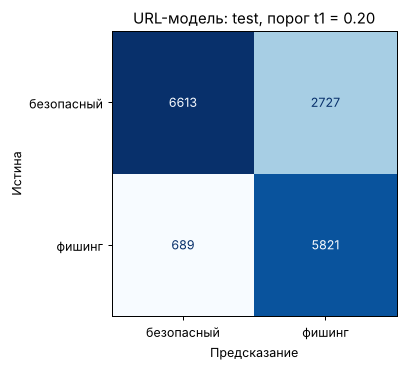

In [11]:
fig, ax = plt.subplots(figsize=(5, 4.2))
p_test = model.predict_proba(data["test"][tu.X_COLS])[:, 1]
ConfusionMatrixDisplay.from_predictions(data["test"]["label"], (p_test >= best["t1"]).astype(int),
                                        display_labels=["безопасный", "фишинг"], cmap="Blues", colorbar=False,
                                        ax=ax, values_format="d")
ax.set_title(f"URL-модель: test, порог t1 = {best['t1']:.2f}")
ax.set_xlabel("Предсказание")
ax.set_ylabel("Истина")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "11_confusion_test_url.png", dpi=150)

In [12]:
test = data["test"].assign(p=p_test.round(3))
print("Пропущенный фишинг (P < t1), примеры:")
print(test[(test["label"] == 1) & (test["p"] < best["t1"])].sort_values("p")[["host", "p"]].head(8).to_string(index=False))
print("\nБезопасные домены с высокой вероятностью (P ≥ t2), примеры:")
print(test[(test["label"] == 0) & (test["p"] >= best["t2"])].sort_values("p", ascending=False)[["host", "p"]].head(8).to_string(index=False))

Пропущенный фишинг (P < t1), примеры:
                   host     p
             sen.org.nz 0.002
        openairradio.hu 0.002
        bowsbride.co.uk 0.002
            vbees.co.uk 0.003
                 ohe.ie 0.007
   orariometromilano.it 0.008
thebodyshelinglogic.com 0.008
     beverlybuckley.org 0.009

Безопасные домены с высокой вероятностью (P ≥ t2), примеры:
                              host     p
               impresa.lapatria.bo 0.995
                         glue.work 0.993
                 support.xerox.com 0.988
                        okcoin.com 0.987
                  nemo.inf.ufes.br 0.983
                     nuevaguia.xyz 0.981
prestigevenuesandevents.sodexo.com 0.980
 observatorio-empresas.vodafone.es 0.979


## 5. Сохранение модели

In [13]:
meta = tu.save(model, best, test_metrics, len(data["train"]))
tu.COMPARISON_PATH.write_text(json.dumps({"algorithms": results, "best": best["name"]}, ensure_ascii=False, indent=1),
                              encoding="utf-8")
print(f"Сохранено: ml/artifacts/url_model.joblib, версия {meta['version']}, пороги {meta['thresholds']}")

Сохранено: ml/artifacts/url_model.joblib, версия 1.0.0, пороги {'t1': 0.2003, 't2': 0.6638}


## 6. Проверка на 20 искусственных URL

10 безопасных — адреса официальных сайтов известных организаций (ссылки не открываются, анализируется только строка);
10 подозрительных — на зарезервированных доменах `.example`, `.test`, `example.com` и адресе документации `192.0.2.0/24`.

In [14]:
safe_urls = ["https://kaspi.kz/shop", "https://halykbank.kz", "https://egov.kz/cms/ru", "https://www.google.com",
             "https://github.com/login", "https://www.wikipedia.org", "https://www.microsoft.com/ru-ru",
             "https://www.apple.com/kz", "https://www.coursera.org", "https://iitu.edu.kz"]
bad_urls = ["http://secure-bank-verify.example/login", "http://192.0.2.15/account-update",
            "http://xn--exmple-cua.test/secure/login?verify=1", "bit.ly/prize-claim-test",
            "http://kaspi-bonus-confirm.test/claim", "https://login-account.example.com/update",
            "http://halykbank-kz.verify-online.example", "http://paypa1.example/signin",
            "http://egov-fines-pay.test/pay?id=4821", "http://free-prize-winner2026.example"]
probe = pd.DataFrame({"url": safe_urls + bad_urls, "ожидание": ["безопасный"] * 10 + ["подозрительный"] * 10})
probe["P_url"] = tu.predict_url_proba(model, probe["url"].tolist()).round(3)
probe["категория"] = [tu.category(p, best["t1"], best["t2"]) for p in probe["P_url"]]
probe["причины (explain_url)"] = [", ".join(explain_url(extract_url_features(u), u)[:2]) for u in probe["url"]]
probe

,url,ожидание,P_url,категория,причины (explain_url)
0,https://kaspi.kz/shop,безопасный,0.265,SUSPICIOUS,
1,https://halykbank.kz,безопасный,0.255,SUSPICIOUS,
2,https://egov.kz/cms/ru,безопасный,0.039,SAFE,
3,https://www.google.com,безопасный,0.571,SUSPICIOUS,
4,https://github.com/login,безопасный,0.474,SUSPICIOUS,Подозрительные слова в адресе: login
5,https://www.wikipedia.org,безопасный,0.044,SAFE,
6,https://www.microsoft.com/ru-ru,безопасный,0.341,SUSPICIOUS,
7,https://www.apple.com/kz,безопасный,0.020,SAFE,
8,https://www.coursera.org,безопасный,0.013,SAFE,
9,https://iitu.edu.kz,безопасный,0.009,SAFE,


## 7. Выводы

1. **Сравнены 2 алгоритма на одинаковых признаках и разбиении.** На validation Logistic Regression: ROC-AUC 0,891, PR-AUC 0,872, F2 при пороге t1 — 0,783; Random Forest: 0,886 / 0,867 / 0,779. Logistic Regression выбрана: качество не хуже, предсказание в 14 раз быстрее (3 мс против 44 мс), коэффициенты интерпретируемы.
2. **Признаки.** Только 17 числовых признаков домена дали ROC-AUC 0,81 на validation: после удаления артефакта разметки модель видит лишь сам домен. Символьные n-граммы домена подняли его до 0,89. По коэффициентам LR сильнее всего на безопасный сайт указывают зоны `.gov`, `.edu`, `.mil`, `.ie`, на фишинг — `.lc`, `.ir`, `.gp`, фрагмент `dns`. Среди числовых признаков у LR — IP-адрес, число поддоменов, Punycode, сокращатель и подозрительная зона; у Random Forest — число поддоменов, доля цифр, число точек и длина домена.
3. **Пороги** (validation): t1 = 0,200 (Recall ≥ 0,85), t2 = 0,664 (Precision ≥ 0,90). Первая версия (t1 по Recall ≥ 0,95) относила к SUSPICIOUS 60% безопасных доменов и была пересмотрена по validation.
4. **Test (итоговая версия):** ROC-AUC 0,921 — требование ≥ 0,90 выполнено. При пороге 0,5 Precision 0,878, Recall 0,792; при t1 Precision 0,681, Recall 0,894; при t2 Precision 0,935, Recall 0,744. Одновременно Precision ≥ 0,85 и Recall ≥ 0,85 не достигаются — требование раздела 3.4 выполнено частично.
5. **Причины.** Многие пропущенные фишинговые домены выглядят как обычные сайты (`sen.org.nz`, `openairradio.hu`) — по-видимому, это взломанные легитимные сайты, на которых размещена фишинговая страница; по строке домена их не отличить. Ложные тревоги — поддомены крупных компаний (`support.xerox.com`, `observatorio-empresas.vodafone.es`) и домены со «словами риска» (`okcoin.com`). Кроме того, все безопасные URL набора — главные страницы популярных сайтов.
6. **20 искусственных URL.** Все 10 подозрительных распознаны: 9 — DANGEROUS (P ≥ 0,98), `paypa1.example` — SUSPICIOUS (0,48). Из 10 безопасных SAFE получили 5; `kaspi.kz`, `halykbank.kz`, `google.com`, `github.com`, `microsoft.com` — SUSPICIOUS (0,26–0,57): короткие домены популярных сервисов модель путает с фишинговыми. Поэтому в приложении действует список официальных доменов (`risk_config.yaml`, `trusted_domains`): ссылка на точный официальный домен получает SAFE, а похожие домены (`kaspl.kz`) под правило не попадают.
7. **Предложения по улучшению:** признаки, вычисляемые без загрузки страницы, но с внешними данными (возраст домена, репутация — ФТ-3.11), набор безопасных URL с путями и с малоизвестных сайтов, отдельная модель для поддоменов хостингов (`*.web.app`, `*.firebaseapp.com`).